# Лабораторная работа 4

Tensorflow 2.x

1) Подготовка данных

2) Использование Keras Model API

3) Использование Keras Sequential + Functional API

https://www.tensorflow.org/tutorials

Для выполнения лабораторной работы необходимо установить tensorflow версии 2.0 или выше .

Рекомендуется использовать возможности Colab'а по обучению моделей на GPU.



In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # убираем служебные сообщения TensorFlow

import pickle
import tensorflow as tf
import numpy as np
import math
import timeit
import matplotlib.pyplot as plt

%matplotlib inline

print('TensorFlow', tf.__version__)

# считаем на GPU, если он есть, иначе на CPU
device = '/device:GPU:0' if tf.config.list_physical_devices('GPU') else '/cpu:0'
print('Device:', device)

# как часто train_part34 печатает loss и accuracy
print_every = 100

# фиксируем seed, чтобы результаты были воспроизводимыми
tf.random.set_seed(231)
np.random.seed(231)

TensorFlow 2.20.0
Device: /cpu:0


# Подготовка данных
Загрузите набор данных из предыдущей лабораторной работы. 

In [ ]:
cifar10_dir = os.path.join('..', '..', 'cifar-10-python', 'cifar-10-batches-py')


def load_cifar_batch(filename):
    """ один батч CIFAR-10 -> X (10000, 32, 32, 3), y (10000,) """
    with open(filename, 'rb') as f:
        d = pickle.load(f, encoding='latin1')
    X = d['data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    y = np.array(d['labels'])
    return X, y


def load_cifar10(num_training=49000, num_validation=1000, num_test=10000):
    """
        Fetch the CIFAR-10 dataset from the web and perform preprocessing to prepare
        it for the two-layer neural net classifier. These are the same steps as
        we used for the SVM, but condensed to a single function.
    """
    xs, ys = [], []
    for b in range(1, 6):
        X, y = load_cifar_batch(os.path.join(cifar10_dir, 'data_batch_%d' % b))
        xs.append(X)
        ys.append(y)
    X_train = np.asarray(np.concatenate(xs), dtype=np.float32)
    y_train = np.asarray(np.concatenate(ys), dtype=np.int32).flatten()
    X_test, y_test = load_cifar_batch(os.path.join(cifar10_dir, 'test_batch'))
    X_test = np.asarray(X_test, dtype=np.float32)
    y_test = np.asarray(y_test, dtype=np.int32).flatten()

    mask = range(num_training, num_training + num_validation)
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = range(num_training)
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = range(num_test)
    X_test = X_test[mask]
    y_test = y_test[mask]

    # нормализация: вычитаем средний пиксель и делим на std (по каждому каналу)
    mean_pixel = X_train.mean(axis=(0, 1, 2), keepdims=True)
    std_pixel = X_train.std(axis=(0, 1, 2), keepdims=True)
    X_train = (X_train - mean_pixel) / std_pixel
    X_val = (X_val - mean_pixel) / std_pixel
    X_test = (X_test - mean_pixel) / std_pixel

    return X_train, y_train, X_val, y_val, X_test, y_test


NHW = (0, 1, 2)
X_train, y_train, X_val, y_val, X_test, y_test = load_cifar10()
print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape, y_train.dtype)
print('Validation data shape: ', X_val.shape)
print('Validation labels shape: ', y_val.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Train data shape:  (49000, 32, 32, 3)
Train labels shape:  (49000,) int32
Validation data shape:  (1000, 32, 32, 3)
Validation labels shape:  (1000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


In [3]:
class Dataset(object):
    def __init__(self, X, y, batch_size, shuffle=False):
        """
        Construct a Dataset object to iterate over data X and labels y
        
        Inputs:
        - X: Numpy array of data, of any shape
        - y: Numpy array of labels, of any shape but with y.shape[0] == X.shape[0]
        - batch_size: Integer giving number of elements per minibatch
        - shuffle: (optional) Boolean, whether to shuffle the data on each epoch
        """
        assert X.shape[0] == y.shape[0], 'Got different numbers of data and labels'
        self.X, self.y = X, y
        self.batch_size, self.shuffle = batch_size, shuffle

    def __iter__(self):
        N, B = self.X.shape[0], self.batch_size
        idxs = np.arange(N)
        if self.shuffle:
            np.random.shuffle(idxs)
        return iter((self.X[i:i+B], self.y[i:i+B]) for i in range(0, N, B))


train_dset = Dataset(X_train, y_train, batch_size=64, shuffle=True)
val_dset = Dataset(X_val, y_val, batch_size=64, shuffle=False)
test_dset = Dataset(X_test, y_test, batch_size=64)

In [4]:
# We can iterate through a dataset like this:
for t, (x, y) in enumerate(train_dset):
    print(t, x.shape, y.shape)
    if t > 5: break

0 (64, 32, 32, 3) (64,)
1 (64, 32, 32, 3) (64,)
2 (64, 32, 32, 3) (64,)
3 (64, 32, 32, 3) (64,)
4 (64, 32, 32, 3) (64,)
5 (64, 32, 32, 3) (64,)
6 (64, 32, 32, 3) (64,)


#  Keras Model Subclassing API


Для реализации собственной модели с помощью Keras Model Subclassing API необходимо выполнить следующие шаги:

1) Определить новый класс, который является наследником tf.keras.Model.

2) В методе __init__() определить все необходимые слои из модуля tf.keras.layer

3) Реализовать прямой проход в методе call() на основе слоев, объявленных в __init__()

Ниже приведен пример использования keras API для определения двухслойной полносвязной сети. 

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras

In [5]:
class TwoLayerFC(tf.keras.Model):
    def __init__(self, hidden_size, num_classes):
        super(TwoLayerFC, self).__init__()        
        initializer = tf.initializers.VarianceScaling(scale=2.0)
        self.fc1 = tf.keras.layers.Dense(hidden_size, activation='relu',
                                   kernel_initializer=initializer)
        self.fc2 = tf.keras.layers.Dense(num_classes, activation='softmax',
                                   kernel_initializer=initializer)
        self.flatten = tf.keras.layers.Flatten()
    
    def call(self, x, training=False):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.fc2(x)
        return x


def test_TwoLayerFC():
    """ A small unit test to exercise the TwoLayerFC model above. """
    input_size, hidden_size, num_classes = 50, 42, 10
    x = tf.zeros((64, input_size))
    model = TwoLayerFC(hidden_size, num_classes)
    with tf.device(device):
        scores = model(x)
        print(scores.shape)
        
test_TwoLayerFC()

(64, 10)


Реализуйте трехслойную CNN для вашей задачи классификации. 

Архитектура сети:
    
1. Сверточный слой (5 x 5 kernels, zero-padding = 'same')
2. Функция активации ReLU 
3. Сверточный слой (3 x 3 kernels, zero-padding = 'same')
4. Функция активации ReLU 
5. Полносвязный слой 
6. Функция активации Softmax 

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/Conv2D

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/Dense

In [6]:
class ThreeLayerConvNet(tf.keras.Model):
    def __init__(self, channel_1, channel_2, num_classes):
        super(ThreeLayerConvNet, self).__init__()
        initializer = tf.initializers.VarianceScaling(scale=2.0)
        # conv 5x5 -> ReLU -> conv 3x3 -> ReLU -> FC -> softmax
        self.conv1 = tf.keras.layers.Conv2D(channel_1, (5, 5), padding='same',
                                            activation='relu', kernel_initializer=initializer)
        self.conv2 = tf.keras.layers.Conv2D(channel_2, (3, 3), padding='same',
                                            activation='relu', kernel_initializer=initializer)
        self.flatten = tf.keras.layers.Flatten()
        self.fc = tf.keras.layers.Dense(num_classes, activation='softmax',
                                        kernel_initializer=initializer)

    def call(self, x, training=False):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.flatten(x)
        scores = self.fc(x)
        return scores

In [7]:
def test_ThreeLayerConvNet():
    channel_1, channel_2, num_classes = 12, 8, 10
    model = ThreeLayerConvNet(channel_1, channel_2, num_classes)
    with tf.device(device):
        # Conv2D в Keras по умолчанию ждёт формат (N, H, W, C)
        x = tf.zeros((64, 32, 32, 3))
        scores = model(x)
        print(scores.shape)

test_ThreeLayerConvNet()

(64, 10)


Пример реализации процесса обучения:

В цикл обучения добавлен декоратор `tf.function` для шага обучения: TensorFlow компилирует его в граф,
и обучение идёт в несколько раз быстрее, чем в eager-режиме. Логика цикла та же, что и в примере.
Функция возвращает обученную модель и accuracy на валидации в конце обучения.

In [ ]:
def train_part34(model_init_fn, optimizer_init_fn, num_epochs=1, is_training=False):
    """
    Simple training loop for use with models defined using tf.keras. It trains
        a model for one epoch on the CIFAR-10 training set and periodically checks
        accuracy on the CIFAR-10 validation set.
        
        Inputs:
        - model_init_fn: A function that takes no parameters; when called it
          constructs the model we want to train: model = model_init_fn()
        - optimizer_init_fn: A function which takes no parameters; when called it
          constructs the Optimizer object we will use to optimize the model:
          optimizer = optimizer_init_fn()
        - num_epochs: The number of epochs to train for
        
    Returns: Nothing, but prints progress during trainingn
    """
    with tf.device(device):

        loss_fn = tf.keras.losses.SparseCategoricalCrossentropy()

        model = model_init_fn()
        optimizer = optimizer_init_fn()

        train_loss = tf.keras.metrics.Mean(name='train_loss')
        train_accuracy = tf.keras.metrics.SparseCategoricalAccuracy(name='train_accuracy')

        val_loss = tf.keras.metrics.Mean(name='val_loss')
        val_accuracy = tf.keras.metrics.SparseCategoricalAccuracy(name='val_accuracy')

        @tf.function
        def train_step(x, y):
            with tf.GradientTape() as tape:
                scores = model(x, training=is_training)
                loss = loss_fn(y, scores)
            gradients = tape.gradient(loss, model.trainable_variables)
            optimizer.apply_gradients(zip(gradients, model.trainable_variables))
            train_loss.update_state(loss)
            train_accuracy.update_state(y, scores)

        @tf.function
        def val_step(x, y):
            prediction = model(x, training=False)
            val_loss.update_state(loss_fn(y, prediction))
            val_accuracy.update_state(y, prediction)

        def evaluate():
            val_loss.reset_state()
            val_accuracy.reset_state()
            for test_x, test_y in val_dset:
                val_step(test_x, test_y)

        t = 0
        for epoch in range(num_epochs):

            # метрики обучения считаем заново в каждой эпохе
            train_loss.reset_state()
            train_accuracy.reset_state()

            for x_np, y_np in train_dset:
                train_step(x_np, y_np)

                if t % print_every == 0:
                    evaluate()
                    template = 'Iteration {}, Epoch {}, Loss: {}, Accuracy: {}, Val Loss: {}, Val Accuracy: {}'
                    print(template.format(t, epoch + 1,
                                          train_loss.result(),
                                          train_accuracy.result() * 100,
                                          val_loss.result(),
                                          val_accuracy.result() * 100))
                t += 1

        # итоговая accuracy на валидации после последней итерации
        evaluate()
        print('End of training: Val Loss: {}, Val Accuracy: {}'.format(
            val_loss.result(), val_accuracy.result() * 100))
        return model, float(val_accuracy.result())

In [9]:
hidden_size, num_classes = 4000, 10
learning_rate = 1e-2

def model_init_fn():
    return TwoLayerFC(hidden_size, num_classes)

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate)

train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 3.216991901397705, Accuracy: 12.5, Val Loss: 2.7120494842529297, Val Accuracy: 11.59999942779541
Iteration 100, Epoch 1, Loss: 2.2312233448028564, Accuracy: 28.805694580078125, Val Loss: 1.8741233348846436, Val Accuracy: 38.60000228881836
Iteration 200, Epoch 1, Loss: 2.076004981994629, Accuracy: 32.734764099121094, Val Loss: 1.799214243888855, Val Accuracy: 40.79999923706055
Iteration 300, Epoch 1, Loss: 2.0031392574310303, Accuracy: 34.14140319824219, Val Loss: 1.873842716217041, Val Accuracy: 37.70000076293945
Iteration 400, Epoch 1, Loss: 1.9348491430282593, Accuracy: 35.75825881958008, Val Loss: 1.7372974157333374, Val Accuracy: 41.70000076293945
Iteration 500, Epoch 1, Loss: 1.8917171955108643, Accuracy: 36.80139923095703, Val Loss: 1.667810320854187, Val Accuracy: 43.5
Iteration 600, Epoch 1, Loss: 1.8607062101364136, Accuracy: 37.71578598022461, Val Loss: 1.703235149383545, Val Accuracy: 42.0
Iteration 700, Epoch 1, Loss: 1.834667682647705, Accuracy:

(<TwoLayerFC name=two_layer_fc_1, built=True>, 0.4620000123977661)

Обучите трехслойную CNN. В tf.keras.optimizers.SGD укажите Nesterov momentum = 0.9 . 

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/optimizers/SGD

Значение accuracy на валидационной выборке после 1 эпохи обучения должно быть > 50% .

In [10]:
learning_rate = 3e-3
channel_1, channel_2, num_classes = 32, 16, 10

def model_init_fn():
    model = ThreeLayerConvNet(channel_1, channel_2, num_classes)
    return model

def optimizer_init_fn():
    # SGD с моментом Нестерова 0.9
    optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate,
                                        momentum=0.9, nesterov=True)
    return optimizer

train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 2.9432859420776367, Accuracy: 15.625, Val Loss: 5.25276517868042, Val Accuracy: 9.5
Iteration 100, Epoch 1, Loss: 2.019495725631714, Accuracy: 31.17264747619629, Val Loss: 1.703561544418335, Val Accuracy: 41.29999923706055
Iteration 200, Epoch 1, Loss: 1.8386280536651611, Accuracy: 36.42723846435547, Val Loss: 1.5283405780792236, Val Accuracy: 47.29999923706055
Iteration 300, Epoch 1, Loss: 1.7391562461853027, Accuracy: 39.2701416015625, Val Loss: 1.4494717121124268, Val Accuracy: 49.5
Iteration 400, Epoch 1, Loss: 1.6564319133758545, Accuracy: 41.91084671020508, Val Loss: 1.4211467504501343, Val Accuracy: 49.79999923706055
Iteration 500, Epoch 1, Loss: 1.598109245300293, Accuracy: 43.696983337402344, Val Loss: 1.3360679149627686, Val Accuracy: 52.499996185302734
Iteration 600, Epoch 1, Loss: 1.5606454610824585, Accuracy: 44.88092803955078, Val Loss: 1.3145544528961182, Val Accuracy: 52.29999923706055
Iteration 700, Epoch 1, Loss: 1.5275088548660278, Accurac

(<ThreeLayerConvNet name=three_layer_conv_net_1, built=True>,
 0.5720000267028809)

# Использование Keras Sequential API для реализации последовательных моделей.

Пример для полносвязной сети:

In [11]:
learning_rate = 1e-2

def model_init_fn():
    input_shape = (32, 32, 3)
    hidden_layer_size, num_classes = 4000, 10
    initializer = tf.initializers.VarianceScaling(scale=2.0)
    layers = [
        tf.keras.Input(shape=input_shape),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(hidden_layer_size, activation='relu',
                              kernel_initializer=initializer),
        tf.keras.layers.Dense(num_classes, activation='softmax',
                              kernel_initializer=initializer),
    ]
    model = tf.keras.Sequential(layers)
    return model

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate)

train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 2.8367655277252197, Accuracy: 7.8125, Val Loss: 2.878476142883301, Val Accuracy: 13.199999809265137
Iteration 100, Epoch 1, Loss: 2.2333757877349854, Accuracy: 28.589109420776367, Val Loss: 1.8905694484710693, Val Accuracy: 38.900001525878906
Iteration 200, Epoch 1, Loss: 2.0684993267059326, Accuracy: 32.447139739990234, Val Loss: 1.8353660106658936, Val Accuracy: 41.400001525878906
Iteration 300, Epoch 1, Loss: 1.9952021837234497, Accuracy: 34.20888900756836, Val Loss: 1.8401578664779663, Val Accuracy: 38.0
Iteration 400, Epoch 1, Loss: 1.9282556772232056, Accuracy: 35.960880279541016, Val Loss: 1.7287559509277344, Val Accuracy: 41.5
Iteration 500, Epoch 1, Loss: 1.8862285614013672, Accuracy: 37.019710540771484, Val Loss: 1.6728845834732056, Val Accuracy: 43.900001525878906
Iteration 600, Epoch 1, Loss: 1.8581031560897827, Accuracy: 37.91597366333008, Val Loss: 1.6952121257781982, Val Accuracy: 41.400001525878906
Iteration 700, Epoch 1, Loss: 1.832881331443

(<Sequential name=sequential, built=True>, 0.4699999988079071)

Альтернативный менее гибкий способ обучения:

In [12]:
model = model_init_fn()
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=learning_rate),
              loss='sparse_categorical_crossentropy',
              metrics=[tf.keras.metrics.sparse_categorical_accuracy])
model.fit(X_train, y_train, batch_size=64, epochs=1, validation_data=(X_val, y_val), verbose=2)
model.evaluate(X_test, y_test, verbose=2)

766/766 - 33s - 42ms/step - loss: 1.8264 - sparse_categorical_accuracy: 0.3876 - val_loss: 1.7007 - val_sparse_categorical_accuracy: 0.4260
313/313 - 3s - 8ms/step - loss: 1.7190 - sparse_categorical_accuracy: 0.4086


[1.7189662456512451, 0.40860000252723694]

Перепишите реализацию трехслойной CNN с помощью tf.keras.Sequential API . Обучите модель двумя способами.

In [13]:
def model_init_fn():
    input_shape = (32, 32, 3)
    channel_1, channel_2, num_classes = 32, 16, 10
    initializer = tf.initializers.VarianceScaling(scale=2.0)
    # та же трёхслойная сеть, но через Sequential
    layers = [
        tf.keras.Input(shape=input_shape),
        tf.keras.layers.Conv2D(channel_1, (5, 5), padding='same', activation='relu',
                               kernel_initializer=initializer),
        tf.keras.layers.Conv2D(channel_2, (3, 3), padding='same', activation='relu',
                               kernel_initializer=initializer),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(num_classes, activation='softmax',
                              kernel_initializer=initializer),
    ]
    model = tf.keras.Sequential(layers)
    return model

learning_rate = 5e-4
def optimizer_init_fn():
    optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate,
                                        momentum=0.9, nesterov=True)
    return optimizer

train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 2.6450183391571045, Accuracy: 4.6875, Val Loss: 2.471710681915283, Val Accuracy: 10.100000381469727
Iteration 100, Epoch 1, Loss: 1.9665781259536743, Accuracy: 29.316213607788086, Val Loss: 1.7852990627288818, Val Accuracy: 37.400001525878906
Iteration 200, Epoch 1, Loss: 1.8528094291687012, Accuracy: 34.35945129394531, Val Loss: 1.6731818914413452, Val Accuracy: 42.29999923706055
Iteration 300, Epoch 1, Loss: 1.7909373044967651, Accuracy: 36.44103240966797, Val Loss: 1.6250684261322021, Val Accuracy: 43.599998474121094
Iteration 400, Epoch 1, Loss: 1.7356209754943848, Accuracy: 38.53257751464844, Val Loss: 1.5788284540176392, Val Accuracy: 46.29999923706055
Iteration 500, Epoch 1, Loss: 1.6989128589630127, Accuracy: 39.89208984375, Val Loss: 1.5303428173065186, Val Accuracy: 47.900001525878906
Iteration 600, Epoch 1, Loss: 1.6724815368652344, Accuracy: 41.00977325439453, Val Loss: 1.4965953826904297, Val Accuracy: 47.60000228881836
Iteration 700, Epoch 1, L

(<Sequential name=sequential_2, built=True>, 0.5019999742507935)

In [14]:
model = model_init_fn()
model.compile(optimizer='sgd',
              loss='sparse_categorical_crossentropy',
              metrics=[tf.keras.metrics.sparse_categorical_accuracy])
model.fit(X_train, y_train, batch_size=64, epochs=1, validation_data=(X_val, y_val), verbose=2)
model.evaluate(X_test, y_test, verbose=2)

766/766 - 14s - 18ms/step - loss: 1.5582 - sparse_categorical_accuracy: 0.4478 - val_loss: 1.3398 - val_sparse_categorical_accuracy: 0.5270
313/313 - 2s - 5ms/step - loss: 1.3621 - sparse_categorical_accuracy: 0.5150


[1.3621068000793457, 0.5149999856948853]

# Использование Keras Functional API

Для реализации более сложных архитектур сети с несколькими входами/выходами, повторным использованием слоев, "остаточными" связями (residual connections) необходимо явно указать входные и выходные тензоры. 

Ниже представлен пример для полносвязной сети. 

In [15]:
def two_layer_fc_functional(input_shape, hidden_size, num_classes):  
    initializer = tf.initializers.VarianceScaling(scale=2.0)
    inputs = tf.keras.Input(shape=input_shape)
    flattened_inputs = tf.keras.layers.Flatten()(inputs)
    fc1_output = tf.keras.layers.Dense(hidden_size, activation='relu',
                                 kernel_initializer=initializer)(flattened_inputs)
    scores = tf.keras.layers.Dense(num_classes, activation='softmax',
                             kernel_initializer=initializer)(fc1_output)

    # Instantiate the model given inputs and outputs.
    model = tf.keras.Model(inputs=inputs, outputs=scores)
    return model

def test_two_layer_fc_functional():
    """ A small unit test to exercise the TwoLayerFC model above. """
    input_size, hidden_size, num_classes = 50, 42, 10
    input_shape = (50,)
    
    x = tf.zeros((64, input_size))
    model = two_layer_fc_functional(input_shape, hidden_size, num_classes)
    
    with tf.device(device):
        scores = model(x)
        print(scores.shape)
        
test_two_layer_fc_functional()

(64, 10)


In [16]:
input_shape = (32, 32, 3)
hidden_size, num_classes = 4000, 10
learning_rate = 1e-2

def model_init_fn():
    return two_layer_fc_functional(input_shape, hidden_size, num_classes)

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate)

train_part34(model_init_fn, optimizer_init_fn)

Iteration 0, Epoch 1, Loss: 3.0055346488952637, Accuracy: 7.8125, Val Loss: 2.9062626361846924, Val Accuracy: 13.0
Iteration 100, Epoch 1, Loss: 2.237358570098877, Accuracy: 28.77475357055664, Val Loss: 1.8707737922668457, Val Accuracy: 39.39999771118164
Iteration 200, Epoch 1, Loss: 2.0743401050567627, Accuracy: 32.57929229736328, Val Loss: 1.8116586208343506, Val Accuracy: 38.80000305175781
Iteration 300, Epoch 1, Loss: 2.001131772994995, Accuracy: 34.338661193847656, Val Loss: 1.855130672454834, Val Accuracy: 39.099998474121094
Iteration 400, Epoch 1, Loss: 1.931994080543518, Accuracy: 36.093360900878906, Val Loss: 1.712734341621399, Val Accuracy: 42.0
Iteration 500, Epoch 1, Loss: 1.887662649154663, Accuracy: 37.04777908325195, Val Loss: 1.660722255706787, Val Accuracy: 42.29999923706055
Iteration 600, Epoch 1, Loss: 1.8573503494262695, Accuracy: 37.91077423095703, Val Loss: 1.6877516508102417, Val Accuracy: 42.0
Iteration 700, Epoch 1, Loss: 1.832011342048645, Accuracy: 38.4785118

(<Functional name=functional_5, built=True>, 0.4569999873638153)

Поэкспериментируйте с архитектурой сверточной сети. Для вашего набора данных вам необходимо получить как минимум 70% accuracy на валидационной выборке за 10 эпох обучения. Опишите все эксперименты и сделайте выводы (без выполнения данного пункта работы приниматься не будут). 

Эспериментируйте с архитектурой, гиперпараметрами, функцией потерь, регуляризацией, методом оптимизации.  

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/BatchNormalization#methods https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/Dropout#methods

### Эксперименты с архитектурой

Чтобы понять, что именно даёт прирост качества, сравниваем несколько вариантов сети. Каждый вариант обучаем 5 эпох
через `model.fit` (Adam, lr=1e-3, батч 64) и сравниваем accuracy на валидации:

1. **base** - трёхслойная сеть из задания (conv 5x5 (32) - conv 3x3 (16) - FC);
2. **vgg** - глубже: 3 блока `[conv 3x3 - ReLU - conv 3x3 - ReLU - max pool]` с 32, 64, 128 фильтрами;
3. **vgg_bn** - то же + BatchNormalization после каждой свёртки;
4. **vgg_bn_dropout** - то же + Dropout после каждого блока (0.2 / 0.3 / 0.4);
5. **vgg_bn_dropout_sgd** - архитектура из п.4, но оптимизатор SGD + Nesterov momentum (lr=1e-2) вместо Adam.

In [17]:
def conv_block(filters, use_bn, dropout):
    """ [conv 3x3 - (BN) - ReLU] x 2 - max pool - (dropout) """
    layers = []
    for _ in range(2):
        layers.append(tf.keras.layers.Conv2D(filters, (3, 3), padding='same', use_bias=not use_bn,
                                             kernel_initializer='he_normal'))
        if use_bn:
            layers.append(tf.keras.layers.BatchNormalization())
        layers.append(tf.keras.layers.ReLU())
    layers.append(tf.keras.layers.MaxPool2D((2, 2)))
    if dropout > 0:
        layers.append(tf.keras.layers.Dropout(dropout))
    return layers


def make_vgg(use_bn=False, dropouts=(0, 0, 0)):
    layers = [tf.keras.Input(shape=(32, 32, 3))]
    for filters, d in zip((32, 64, 128), dropouts):
        layers += conv_block(filters, use_bn, d)
    layers += [tf.keras.layers.Flatten(),
               tf.keras.layers.Dense(10, activation='softmax')]
    return tf.keras.Sequential(layers)


def make_base():
    initializer = tf.initializers.VarianceScaling(scale=2.0)
    return tf.keras.Sequential([
        tf.keras.Input(shape=(32, 32, 3)),
        tf.keras.layers.Conv2D(32, (5, 5), padding='same', activation='relu', kernel_initializer=initializer),
        tf.keras.layers.Conv2D(16, (3, 3), padding='same', activation='relu', kernel_initializer=initializer),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(10, activation='softmax', kernel_initializer=initializer),
    ])


experiments = {
    'base':               (make_base, lambda: tf.keras.optimizers.Adam(1e-3)),
    'vgg':                (lambda: make_vgg(), lambda: tf.keras.optimizers.Adam(1e-3)),
    'vgg_bn':             (lambda: make_vgg(use_bn=True), lambda: tf.keras.optimizers.Adam(1e-3)),
    'vgg_bn_dropout':     (lambda: make_vgg(use_bn=True, dropouts=(0.2, 0.3, 0.4)),
                           lambda: tf.keras.optimizers.Adam(1e-3)),
    'vgg_bn_dropout_sgd': (lambda: make_vgg(use_bn=True, dropouts=(0.2, 0.3, 0.4)),
                           lambda: tf.keras.optimizers.SGD(1e-2, momentum=0.9, nesterov=True)),
}

histories = {}
for name, (make_model, make_opt) in experiments.items():
    tf.random.set_seed(231)
    model = make_model()
    model.compile(optimizer=make_opt(),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    print('=== %s: %d параметров' % (name, model.count_params()))
    with tf.device(device):
        h = model.fit(X_train, y_train, batch_size=64, epochs=5,
                      validation_data=(X_val, y_val), verbose=2)
    histories[name] = h.history

=== base: 170906 параметров
Epoch 1/5
766/766 - 15s - 20ms/step - accuracy: 0.4730 - loss: 1.5350 - val_accuracy: 0.5670 - val_loss: 1.2493
Epoch 2/5
766/766 - 13s - 17ms/step - accuracy: 0.6189 - loss: 1.0970 - val_accuracy: 0.5860 - val_loss: 1.1957
Epoch 3/5
766/766 - 13s - 17ms/step - accuracy: 0.6896 - loss: 0.9085 - val_accuracy: 0.5870 - val_loss: 1.2222
Epoch 4/5
766/766 - 14s - 18ms/step - accuracy: 0.7438 - loss: 0.7552 - val_accuracy: 0.5780 - val_loss: 1.3466
Epoch 5/5
766/766 - 13s - 17ms/step - accuracy: 0.7898 - loss: 0.6280 - val_accuracy: 0.5770 - val_loss: 1.4753
=== vgg: 307498 параметров
Epoch 1/5
766/766 - 46s - 60ms/step - accuracy: 0.5031 - loss: 1.3891 - val_accuracy: 0.6080 - val_loss: 1.0555
Epoch 2/5
766/766 - 42s - 55ms/step - accuracy: 0.6804 - loss: 0.9192 - val_accuracy: 0.7180 - val_loss: 0.8229
Epoch 3/5
766/766 - 41s - 53ms/step - accuracy: 0.7540 - loss: 0.7161 - val_accuracy: 0.7340 - val_loss: 0.7602
Epoch 4/5
766/766 - 41s - 53ms/step - accuracy: 0

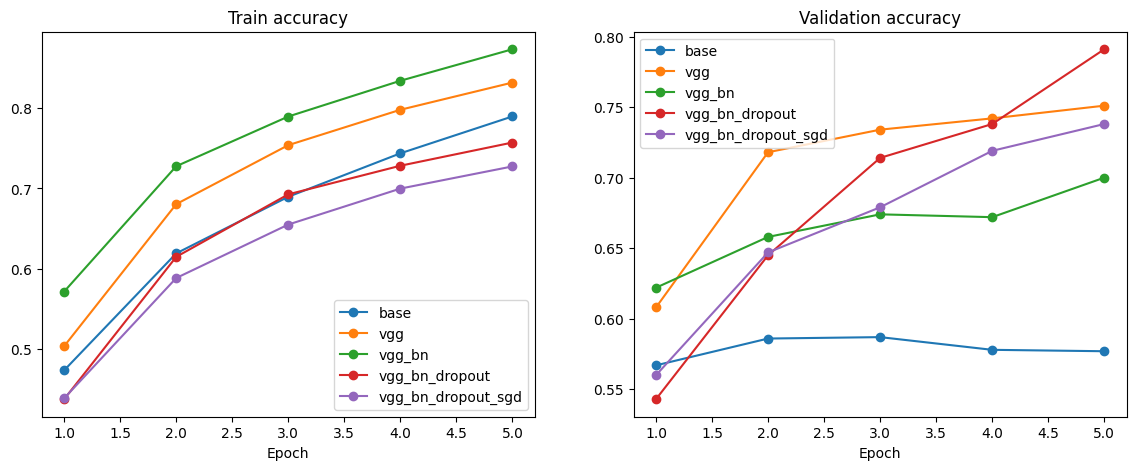

model                 train acc    val acc   best val
base                      0.790      0.577      0.587
vgg                       0.832      0.751      0.751
vgg_bn                    0.874      0.700      0.700
vgg_bn_dropout            0.757      0.791      0.791
vgg_bn_dropout_sgd        0.727      0.738      0.738


In [18]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
for name, h in histories.items():
    plt.plot(range(1, 6), h['accuracy'], '-o', label=name)
plt.title('Train accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
for name, h in histories.items():
    plt.plot(range(1, 6), h['val_accuracy'], '-o', label=name)
plt.title('Validation accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()

print('%-20s %10s %10s %10s' % ('model', 'train acc', 'val acc', 'best val'))
for name, h in histories.items():
    print('%-20s %10.3f %10.3f %10.3f' % (name, h['accuracy'][-1], h['val_accuracy'][-1],
                                          max(h['val_accuracy'])))

### Итоговая модель

Лучший вариант из экспериментов (**vgg_bn_dropout**) реализован через Model Subclassing API и обучается 10 эпох в `train_part34`.

In [19]:
class CustomConvNet(tf.keras.Model):
    """
    VGG-подобная сеть (лучший вариант из экспериментов):
    3 блока [conv 3x3 - BN - ReLU - conv 3x3 - BN - ReLU - max pool - dropout]
    с 32, 64, 128 фильтрами, затем полносвязный слой с softmax.
    """
    def __init__(self):
        super(CustomConvNet, self).__init__()
        self.blocks = []
        for filters, drop in zip((32, 64, 128), (0.2, 0.3, 0.4)):
            block = []
            for _ in range(2):
                block.append(tf.keras.layers.Conv2D(filters, (3, 3), padding='same', use_bias=False,
                                                    kernel_initializer='he_normal'))
                block.append(tf.keras.layers.BatchNormalization())
                block.append(tf.keras.layers.ReLU())
            block.append(tf.keras.layers.MaxPool2D((2, 2)))
            block.append(tf.keras.layers.Dropout(drop))
            self.blocks.append(block)
        self.flatten = tf.keras.layers.Flatten()
        self.fc = tf.keras.layers.Dense(10, activation='softmax')

    def call(self, input_tensor, training=False):
        x = input_tensor
        for block in self.blocks:
            for layer in block:
                # BatchNorm и Dropout ведут себя по-разному при обучении и на тесте
                if isinstance(layer, (tf.keras.layers.BatchNormalization, tf.keras.layers.Dropout)):
                    x = layer(x, training=training)
                else:
                    x = layer(x)
        x = self.flatten(x)
        x = self.fc(x)
        return x


print_every = 700
num_epochs = 10

tf.random.set_seed(231)

def model_init_fn():
    return CustomConvNet()

def optimizer_init_fn():
    learning_rate = 1e-3
    return tf.keras.optimizers.Adam(learning_rate)

custom_model, custom_val_acc = train_part34(model_init_fn, optimizer_init_fn,
                                            num_epochs=num_epochs, is_training=True)

Iteration 0, Epoch 1, Loss: 4.227048873901367, Accuracy: 10.9375, Val Loss: 3.5657527446746826, Val Accuracy: 11.399999618530273
Iteration 700, Epoch 1, Loss: 1.6541177034378052, Accuracy: 42.86064529418945, Val Loss: 1.268548607826233, Val Accuracy: 55.29999542236328
Iteration 1400, Epoch 2, Loss: 1.0802699327468872, Accuracy: 61.63877868652344, Val Loss: 0.9607646465301514, Val Accuracy: 67.19999694824219
Iteration 2100, Epoch 3, Loss: 0.8914747834205627, Accuracy: 68.5824966430664, Val Loss: 0.7869516611099243, Val Accuracy: 73.0
Iteration 2800, Epoch 4, Loss: 0.7819228172302246, Accuracy: 72.29125213623047, Val Loss: 0.7985806465148926, Val Accuracy: 73.29999542236328
Iteration 3500, Epoch 5, Loss: 0.7108849287033081, Accuracy: 75.03575897216797, Val Loss: 0.6241360902786255, Val Accuracy: 78.0999984741211
Iteration 4200, Epoch 6, Loss: 0.6572670340538025, Accuracy: 76.78571319580078, Val Loss: 0.6283578276634216, Val Accuracy: 78.89999389648438
Iteration 4900, Epoch 7, Loss: 0.600

In [20]:
# итоговая модель на тестовой выборке (10 000 картинок)
test_acc = tf.keras.metrics.SparseCategoricalAccuracy()
for x, y in test_dset:
    test_acc.update_state(y, custom_model(x, training=False))
print('Validation accuracy: %.4f' % custom_val_acc)
print('Test accuracy:       %.4f' % float(test_acc.result()))

Validation accuracy: 0.8320
Test accuracy:       0.8195


Опишите все эксперименты, результаты. Сделайте выводы.

### Результаты по разделам

| Модель | API / способ обучения | Оптимизатор | Accuracy на val после 1 эпохи |
|---|---|---|---|
| Двухслойная FC (4000 нейронов) | Subclassing, `train_part34` | SGD, lr=1e-2 | 46.2% |
| Трёхслойная CNN (conv5x5(32) - conv3x3(16) - FC) | Subclassing, `train_part34` | SGD + Nesterov 0.9, lr=3e-3 | **57.2%** (> 50%) |
| Двухслойная FC | Sequential, `train_part34` | SGD, lr=1e-2 | 47.0% |
| Двухслойная FC | Sequential, `fit` | SGD, lr=1e-2 | 42.6% (test 40.9%) |
| Трёхслойная CNN | Sequential, `train_part34` | SGD + Nesterov 0.9, lr=5e-4 | 50.2% |
| Трёхслойная CNN | Sequential, `fit` | SGD (по умолчанию lr=1e-2) | 52.7% (test 51.5%) |
| Двухслойная FC | Functional API, `train_part34` | SGD, lr=1e-2 | 45.7% |

Все три способа описания модели (Subclassing, Sequential, Functional) дают одинаковые по архитектуре сети, и результаты у них близкие.
Разница в 1-5% объясняется случайной инициализацией и порядком батчей. Свёрточная сеть уже после одной эпохи заметно лучше полносвязной (≈50-57% против ≈43-47%),
хотя параметров у неё меньше: свёртки учитывают пространственную структуру картинки.

### Эксперименты с архитектурой (5 эпох, Adam lr=1e-3)

| Вариант | Параметров | Train acc | Val acc |
|---|---|---|---|
| base - трёхслойная CNN из задания | 171 тыс. | 0.790 | 0.577 (лучшая 0.587) |
| vgg - 3 блока по 2 свёртки 3x3 + max pool | 307 тыс. | 0.832 | 0.751 |
| vgg_bn - + BatchNorm | 309 тыс. | 0.874 | 0.700 |
| vgg_bn_dropout - + BatchNorm + Dropout | 309 тыс. | 0.757 | **0.791** |
| vgg_bn_dropout_sgd - то же, SGD + Nesterov (lr=1e-2) | 309 тыс. | 0.727 | 0.738 |

1. **Глубина и pooling.** Переход от трёхслойной сети к VGG-подобной (больше свёрток 3x3, max pooling, число фильтров растёт 32 → 64 → 128) поднял val accuracy с ≈0.58 до ≈0.75.
   Трёхслойная сеть быстро переобучается: train растёт до 0.79, а val после 2-й эпохи стоит на месте и даже падает (loss на val растёт).
2. **BatchNorm** ускоряет обучение (train accuracy выше на каждой эпохе), но без другой регуляризации переобучение сильнее: train 0.87, val 0.70.
   Кроме того, на val при BN результат сильнее «скачет» между эпохами.
3. **Dropout** (0.2 / 0.3 / 0.4 после блоков) убрал переобучение. Train accuracy ниже (0.76), а val самая высокая (0.79) и продолжает расти. Разрыв train/val почти исчез, так что модель можно учить дольше.
4. **Оптимизатор.** С той же архитектурой SGD + Nesterov (lr=1e-2) сходится медленнее Adam: 0.738 против 0.791 за 5 эпох.

### Итоговая модель

`CustomConvNet` (Model Subclassing API): 3 блока `[conv3x3 - BN - ReLU] x 2 - max pool - dropout` с 32/64/128 фильтрами, затем Dense(10) + softmax.
Adam, lr=1e-3, батч 64, 10 эпох, `train_part34` с `is_training=True` (BatchNorm и Dropout работают в режиме обучения).

- accuracy на валидации после 10 эпох: **83.2%** (требование - не менее 70%);
- accuracy на тестовой выборке (10 000 изображений): **81.95%**.

### Выводы

- Keras даёт три способа описать модель. **Sequential** - самый короткий, подходит для простой цепочки слоёв.
  **Functional API** нужен для нелинейных архитектур (несколько входов/выходов, residual-связи). **Model Subclassing** - самый гибкий:
  прямой проход пишется вручную, и можно явно управлять режимом `training`.
- Обучать модель можно своим циклом с `tf.GradientTape` (полный контроль над шагом обучения) или через `compile` + `fit` (меньше кода).
  Обёртка шага обучения в `tf.function` заметно ускоряет собственный цикл.
- Для CIFAR-10 качество больше всего подняли: более глубокая сеть с маленькими свёртками и pooling, BatchNorm (быстрая сходимость)
  и Dropout (борьба с переобучением). Вместе они дали рост с ≈58% до ≈83% на валидации при том же числе эпох обучения.